In [1]:
# === Ô GHI LOG (mẫu PL1 bản 2 – chạy được với ipykernel 7): mọi thứ in ra màn hình đồng thời được ghi vào file log ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "02_E0.7_rq1_chu_ky_va_cong_to_phu_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-14 00:01:53 | INFO | Bắt đầu chạy 02_E0.7_rq1_chu_ky_va_cong_to_phu_Han – người chạy: Han – file log: /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy/logs/eda_log/2026-11-14_0001_02_E0.7_rq1_chu_ky_va_cong_to_phu_Han.log


# E0.7 – RQ1: chu kỳ (tự tương quan) và công tơ phụ theo giờ

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 13/11/2026 |
| **Thí nghiệm** | E0.7 – RQ1: chu kỳ (tự tương quan) và công tơ phụ theo giờ |
| **Mục đích** | Tách từ `02_eda.ipynb`: RQ1 (e), (f) (mục 7, 8). |
| **Đọc vào** | `data/processed/hourly_clean.csv` (do `01_cleaning` tạo) |
| **Ghi ra** | `figures/eda_figures/02_rq1_acf.*`, `data/eda_data/eda_rq1_submeter_theo_gio.csv`, `figures/eda_figures/02_rq1_submeter_theo_gio.*` |
| **Chạy sau** | `01_cleaning.ipynb` (cần `hourly_clean.csv`) |

Notebook EDA chỉ đọc và mô tả dữ liệu, không sửa, không xoá, không điền dữ liệu. Bản gộp đọc từ trên xuống: `00_EDA_tong_hop_Han.ipynb`.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda_notebooks/
FILE = ROOT / "data" / "processed" / "hourly_clean.csv"
DIR_DATA = ROOT / "data" / "eda_data"
DIR_FIG = ROOT / "figures" / "eda_figures"
DIR_FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "svg.fonttype": "none"})

MEAN_COLS = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity"]
SUB_COLS = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
COLS = MEAN_COLS + SUB_COLS
TARGET = "Global_active_power"
VAR_RQ2 = ["Voltage", "Global_intensity", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]

DOW_LABEL = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
SEASON_ORDER = ["Xuân", "Hè", "Thu", "Đông"]
PERIOD_LABEL = {1: "Năm 1\n12/2006–11/2007", 2: "Năm 2\n12/2007–11/2008",
                3: "Năm 3\n12/2008–11/2009", 4: "Năm 4\n12/2009–11/2010"}

def season_of(m):
    """Mùa theo khí hậu Pháp (bắc bán cầu): Đông 12-2, Xuân 3-5, Hè 6-8, Thu 9-11."""
    if m in (12, 1, 2): return "Đông"
    if m in (3, 4, 5): return "Xuân"
    if m in (6, 7, 8): return "Hè"
    return "Thu"

def vn(x, d=3):
    """Số kiểu Việt Nam: dấu phẩy thập phân."""
    return f"{x:.{d}f}".replace(".", ",")

def fmt(n):
    return f"{int(n):,}".replace(",", ".")

def strength(r):
    a = abs(r)
    if a >= 0.7: return "mạnh"
    if a >= 0.4: return "trung bình"
    if a >= 0.2: return "yếu"
    return "rất yếu"

def save_fig(name):
    plt.savefig(DIR_FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.savefig(DIR_FIG / f"{name}.svg", bbox_inches="tight")

notes = []   # các câu gợi ý nhận xét (số liệu tự điền)
def add_note(tag, text):
    notes.append(f"- **[{tag}]** {text}")

In [3]:
raw = pd.read_csv(FILE, parse_dates=["datetime"], index_col="datetime")
assert (raw.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), "Trục giờ không liên tục"

df = raw[COLS].copy()                       # chỉ 7 cột gốc, không dùng *_ffill
df["hour"] = df.index.hour
df["dow"] = df.index.dayofweek              # 0 = thứ 2 ... 6 = chủ nhật
df["is_weekend"] = df["dow"] >= 5
df["month"] = df.index.month
df["season"] = df["month"].map(season_of)
# Năm vận hành: tháng 12 đến tháng 11 năm sau (khớp với khoảng dữ liệu 12/2006 đến 11/2010)
df["period"] = np.asarray(((df.index.year * 12 + df.index.month) - (2006 * 12 + 12)) // 12 + 1)

n_all = len(df)
n_valid = int(df[TARGET].notna().sum())
print(f"Tổng số giờ: {fmt(n_all)} | Giờ có số đo thật: {fmt(n_valid)} | Giờ thiếu (bỏ qua): {fmt(n_all - n_valid)}")
print("Khoảng thời gian:", df.index[0], "->", df.index[-1])
print("Số giờ có số đo theo mùa:\n", df.groupby("season")[TARGET].count().reindex(SEASON_ORDER))
df.head()

Tổng số giờ: 34.588 | Giờ có số đo thật: 34.157 | Giờ thiếu (bỏ qua): 431
Khoảng thời gian: 2006-12-16 17:00:00 -> 2010-11-26 20:00:00
Số giờ có số đo theo mùa:
 season
Xuân    8736
Hè      8639
Thu     8549
Đông    8233
Name: Global_active_power, dtype: int64


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,hour,dow,is_weekend,month,season,period
datetime,,,,,,,,,,,,,
2006-12-16 17:00:00,4.2229,0.2290,234.6439,18.1000,0.0,31.6667,1011.6667,17,5,True,12,Đông,1
2006-12-16 18:00:00,3.6322,0.0800,234.5802,15.6000,0.0,403.0000,1012.0000,18,5,True,12,Đông,1
2006-12-16 19:00:00,3.4002,0.0852,233.2325,14.5033,0.0,86.0000,1001.0000,19,5,True,12,Đông,1
2006-12-16 20:00:00,3.2686,0.0751,234.0715,13.9167,0.0,0.0000,1007.0000,20,5,True,12,Đông,1
2006-12-16 21:00:00,3.0565,0.0767,237.1587,13.0467,0.0,25.0000,1033.0000,21,5,True,12,Đông,1


In [4]:
MA_TN = "E0.7"
moc_note = len(notes)    # các câu gợi ý nhận xét từ đây trở đi thuộc E0.7

## 7. RQ1 (e): Chu kỳ của chuỗi (tự tương quan)
Tự tương quan (ACF) của `Global_active_power` theo độ trễ 1 đến 200 giờ. Nếu chuỗi có chu kỳ ngày và tuần thì ACF có đỉnh tại bội số của 24 giờ và tại 168 giờ. Đây là bằng chứng mô tả cho việc chọn đặc trưng trễ 24h và 168h ở bước sau (các lag này đã nêu trong Proposal, chưa dựa vào Test).

Các đỉnh ACF cao nhất (độ trễ, hệ số): [(168, 0.461), (24, 0.436), (72, 0.412), (96, 0.403), (48, 0.401), (144, 0.397)]


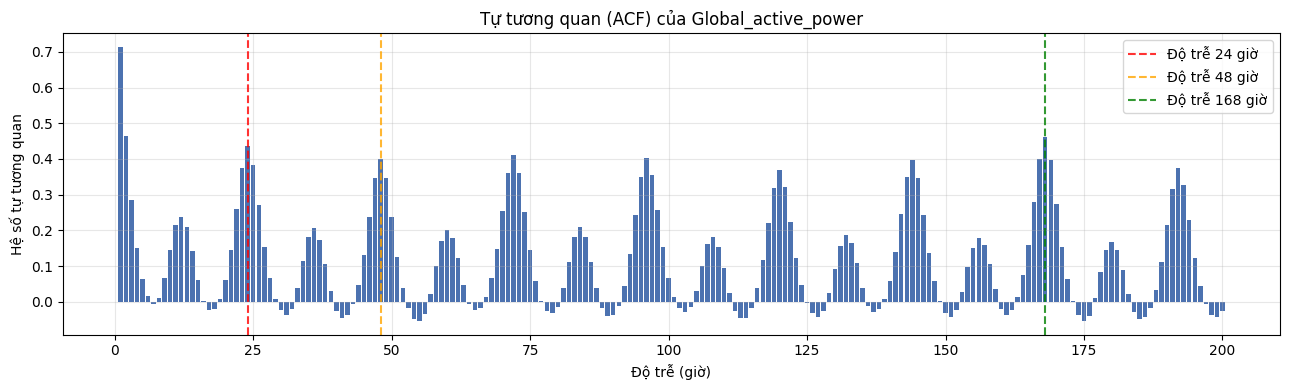

1      0.713
2      0.465
12     0.239
23     0.376
24     0.436
25     0.383
48     0.401
167    0.400
168    0.461
169    0.398
dtype: float64

In [5]:
lags = np.arange(1, 201)
acf = pd.Series([df[TARGET].autocorr(int(l)) for l in lags], index=lags)
a = acf.values
peaks = [(int(lags[i]), float(a[i])) for i in range(1, len(a) - 1) if a[i] > a[i - 1] and a[i] > a[i + 1]]
top_peaks = sorted(peaks, key=lambda t: -t[1])[:6]
print("Các đỉnh ACF cao nhất (độ trễ, hệ số):", [(l, round(v, 3)) for l, v in top_peaks])

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(acf.index, acf.values, width=0.8, color="#4C72B0")
for L, c in [(24, "red"), (48, "orange"), (168, "green")]:
    ax.axvline(L, color=c, linestyle="--", alpha=0.8, label=f"Độ trễ {L} giờ")
ax.set_title("Tự tương quan (ACF) của Global_active_power")
ax.set_xlabel("Độ trễ (giờ)"); ax.set_ylabel("Hệ số tự tương quan"); ax.legend()
plt.tight_layout()
save_fig("02_rq1_acf")
plt.show()
acf.loc[[1, 2, 12, 23, 24, 25, 48, 167, 168, 169]].round(3)

In [6]:
add_note("RQ1-chu kỳ", f"Hệ số tự tương quan tại độ trễ 1 giờ là {vn(acf.loc[1])}; tại 12 giờ là {vn(acf.loc[12])}; "
         f"tại 24 giờ là {vn(acf.loc[24])}; tại 48 giờ là {vn(acf.loc[48])}; tại 168 giờ là {vn(acf.loc[168])}.")
add_note("RQ1-chu kỳ", "Các đỉnh tự tương quan cao nhất (không kể độ trễ 1) xuất hiện tại độ trễ: " +
         ", ".join(f"{l} giờ ({vn(v)})" for l, v in top_peaks) + ".")

**Nhận xét:** Tự tương quan ở độ trễ 1 giờ là 0,713, độ trễ 24 giờ là 0,436 và độ trễ 168 giờ là 0,461 (cao nhất sau độ trễ 1); độ trễ 12 giờ chỉ 0,239. Chuỗi có chu kỳ ngày và tuần rõ. Đây là cơ sở để chọn đặc trưng trễ 1, 24 và 168 giờ.

## 8. RQ1 (f), bổ sung: Công tơ phụ theo giờ
Hình này giúp **giải thích** đỉnh công suất theo giờ: khu vực nào (bếp, phòng giặt, nước nóng và điều hòa) tăng vào thời điểm nào. Sub_metering là Wh tiêu thụ mỗi giờ (đã tổng hợp theo giờ ở bước làm sạch).

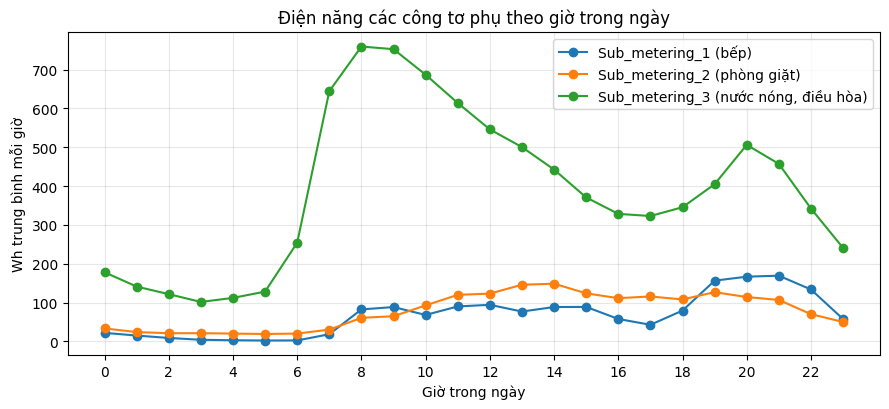

In [7]:
sub_prof = df.groupby("hour")[SUB_COLS].mean()
sub_prof.round(4).to_csv(DIR_DATA / "eda_rq1_submeter_theo_gio.csv", index_label="gio")
fig, ax = plt.subplots(figsize=(9, 4.2))
for c, lab in zip(SUB_COLS, ["Sub_metering_1 (bếp)", "Sub_metering_2 (phòng giặt)", "Sub_metering_3 (nước nóng, điều hòa)"]):
    ax.plot(sub_prof.index, sub_prof[c], marker="o", label=lab)
ax.set_title("Điện năng các công tơ phụ theo giờ trong ngày")
ax.set_xlabel("Giờ trong ngày"); ax.set_ylabel("Wh trung bình mỗi giờ"); ax.set_xticks(range(0, 24, 2)); ax.legend()
plt.tight_layout()
save_fig("02_rq1_submeter_theo_gio")
plt.show()

for c in SUB_COLS:
    h = int(sub_prof[c].idxmax())
    add_note("RQ1-công tơ phụ", f"{c} đạt trung bình cao nhất lúc {h}h ({vn(sub_prof.loc[h, c], 1)} Wh/giờ), thấp nhất lúc {int(sub_prof[c].idxmin())}h ({vn(sub_prof[c].min(), 1)} Wh/giờ).")

**Nhận xét:** Ba công tơ phụ có giờ cao điểm khác nhau: Sub_metering_3 (máy nước nóng, điều hòa) lúc 8h (759,5 Wh/giờ), Sub_metering_2 (phòng giặt) lúc 14h (148,5), Sub_metering_1 (bếp) lúc 21h (169,2). Cả ba cùng thấp nhất khoảng 3h đến 5h sáng. Mỗi nhóm thiết bị có giờ hoạt động riêng, góp phần giải thích hai đỉnh công suất trong ngày.

## Gợi ý nhận xét E0.7 (số tự điền)

In [8]:
goi_y = "\n".join(notes[moc_note:])
(DIR_DATA / f"eda_{MA_TN}_goi_y_nhan_xet.md").write_text(goi_y, encoding="utf-8")
log.info(f"Gợi ý nhận xét {MA_TN} (số tự điền), lưu ở data/eda_data/eda_{MA_TN}_goi_y_nhan_xet.md:\n" + goi_y)

2026-11-14 00:01:54 | INFO | Gợi ý nhận xét E0.7 (số tự điền), lưu ở data/eda_E0.7_goi_y_nhan_xet.md:
- **[RQ1-chu kỳ]** Hệ số tự tương quan tại độ trễ 1 giờ là 0,713; tại 12 giờ là 0,239; tại 24 giờ là 0,436; tại 48 giờ là 0,401; tại 168 giờ là 0,461.
- **[RQ1-chu kỳ]** Các đỉnh tự tương quan cao nhất (không kể độ trễ 1) xuất hiện tại độ trễ: 168 giờ (0,461), 24 giờ (0,436), 72 giờ (0,412), 96 giờ (0,403), 48 giờ (0,401), 144 giờ (0,397).
- **[RQ1-công tơ phụ]** Sub_metering_1 đạt trung bình cao nhất lúc 21h (169,2 Wh/giờ), thấp nhất lúc 5h (2,1 Wh/giờ).
- **[RQ1-công tơ phụ]** Sub_metering_2 đạt trung bình cao nhất lúc 14h (148,5 Wh/giờ), thấp nhất lúc 5h (18,9 Wh/giờ).
- **[RQ1-công tơ phụ]** Sub_metering_3 đạt trung bình cao nhất lúc 8h (759,5 Wh/giờ), thấp nhất lúc 3h (101,5 Wh/giờ).


## Log lên W&B (minh chứng)

In [9]:
# W&B (project cuoi-ky-du-bao-dien-nang). Mặc định TẮT để chạy lại không tạo run trùng.
# Muốn ghi lên W&B: chạy notebook bằng lệnh  BAT_WANDB=1 jupyter nbconvert --to notebook --execute --inplace <notebook>
import os
USE_WANDB = os.environ.get("BAT_WANDB") == "1"
if USE_WANDB:
    import wandb, pandas as pd
    BANG = ['eda_rq1_submeter_theo_gio.csv']
    HINH = ['02_rq1_acf.png', '02_rq1_submeter_theo_gio.png']
    run = wandb.init(entity="sgu-mayhoc-nhom11", project="cuoi-ky-du-bao-dien-nang",
                     name="ck-E0.7-Han-rq1-chu-ky-va-cong-to-phu", tags=["E0.7", "Han", "EDA"],
                     config={"notebook": TEN_NOTEBOOK, "file_log": str(file_log)})
    run.summary.update({"acf_tre_1h": float(acf.loc[1]), "acf_tre_24h": float(acf.loc[24]), "acf_tre_168h": float(acf.loc[168])})
    run.log({**{"bang/" + b.removesuffix(".csv"): wandb.Table(dataframe=pd.read_csv(DIR_DATA / b)) for b in BANG},
             **{"hinh/" + h.removesuffix(".png"): wandb.Image(str(DIR_FIG / h)) for h in HINH},
             "ket_luan": wandb.Html("<br>".join(str(x) for x in notes[moc_note:]))})
    log.info(f"Đã ghi W&B: {run.url}")
    run.finish()

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from /Users/caongochan/.netrc.


wandb: Currently logged in as: caongochan142 (sgu-mayhoc-nhom11) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


wandb: setting up run y9hs8r2h


wandb: Tracking run with wandb version 0.31.0


wandb: Run data is saved locally in /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy/notebooks/eda/wandb/run-20261114_000155-y9hs8r2h
wandb: Run `wandb offline` to turn off syncing.


wandb: Syncing run ck-E0.7-Han-rq1-chu-ky-va-cong-to-phu


... (7 outputs left out)

wandb: uploading history steps 0-0, summary, console lines 0-0


wandb: 
wandb: Run summary:
wandb: acf_tre_168h 0.46128
wandb:   acf_tre_1h 0.7135
wandb:  acf_tre_24h 0.43605
wandb: 


wandb: 🚀 View run ck-E0.7-Han-rq1-chu-ky-va-cong-to-phu at: https://forge.coreweave.com/wandb/sgu-mayhoc-nhom11/cuoi-ky-du-bao-dien-nang/runs/y9hs8r2h
wandb: ⭐️ View project at: https://forge.coreweave.com/wandb/sgu-mayhoc-nhom11/cuoi-ky-du-bao-dien-nang
wandb: Synced 5 W&B file(s), 4 media file(s), 2 artifact file(s) and 0 other file(s)


wandb: Find logs at: ./wandb/run-20261114_000155-y9hs8r2h/logs


## Nhật ký

- 01/11/2026 – Viết lần đầu trong notebook `02_eda.ipynb`. Commit `74a9949`.
- 07/11/2026 – Sửa `02_eda.ipynb`. Commit `9a1f293`, `910a450`.
- 13/11/2026 – Tách RQ1 (e), (f) (mục 7, 8) ra khỏi `02_eda.ipynb` thành notebook riêng `02_E0.7_rq1_chu_ky_va_cong_to_phu_Han.ipynb`, thêm ô ghi log. Commit `cdf1bfd` (lúc này notebook chưa chạy).
- 13/11/2026 – Chạy lúc 19:59, commit log và bảng kết quả. Commit `3dc70b7`.
- 13/11/2026 – Lưu notebook có output (commit trước chưa kèm notebook đã chạy). Commit `5754d82`.
- 13/11/2026 – Chuyển các file log EDA vào `logs/eda_log/` và sửa ô ghi log để các lần chạy sau ghi thẳng vào thư mục này. Commit `44b69dd`.